# 02 — Preparação das features e desenho da validação

Continua o notebook 01. Mostra a tabela `features` (local × trimestre), o pré-processamento
(`src/modelagem/pipeline.py`), a divisão temporal e a validação cruzada temporal
(`src/modelagem/validacao.py`), e o contraste com o k-fold estratificado pedido na seção 4 do
`ARCHITECTURE.md`.

## 1. A tabela de features

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
PROC = RAIZ / "data" / "processed"
import sys
sys.path.insert(0, str(RAIZ))
from src.modelagem.pipeline import colunas_do_modelo, matriz, preprocessador, montar_pipeline
from src.modelagem.validacao import PERIODOS, folds_temporais, split_temporal
from src.preparo.features import ALVOS

features = pd.read_parquet(PROC / "features.parquet")
numericas, categoricas = colunas_do_modelo(features)
print(f"{len(features):,} linhas = {features['local_id'].nunique()} locais × {features['trimestre'].nunique()} trimestres")
print(f"{len(numericas)} numéricas, {len(categoricas)} categóricas + bairro; alvos: {ALVOS}")

70,473 linhas = 1807 locais × 39 trimestres
37 numéricas, 12 categóricas + bairro; alvos: ['y_vitima', 'y_atropelamento']


In [2]:
grupos = {
    "histórico no local": [c for c in numericas if c.startswith(("acidentes_", "rel_", "trimestres_"))],
    "perfil horário": [c for c in numericas if c.startswith(("frac_", "hora_"))],
    "cruzamento": ["tem_cruzamento_registrado", "n_vias_transversais"],
    "envolvidos (média histórica)": [c for c in numericas if c.startswith("media_")],
    "via (último valor conhecido)": ["velocidade_max_via", "tem_semaforo"] + categoricas[:-2],
    "contexto (mais frequente)": categoricas[-2:],
    "temporal": ["ano", "trimestre_do_ano", "periodo_pandemia"],
}
pd.Series({g: ", ".join(c) for g, c in grupos.items()}).to_frame("colunas")

,colunas
histórico no local,"acidentes_1t, rel_acidentes_1t, acidentes_2t, ..."
perfil horário,"frac_madrugada, frac_manha, frac_tarde, frac_n..."
cruzamento,"tem_cruzamento_registrado, n_vias_transversais"
envolvidos (média histórica),"media_auto, media_moto, media_ciclom, media_ci..."
via (último valor conhecido),"velocidade_max_via, tem_semaforo, sinalizacao,..."
contexto (mais frequente),"tempo_clima_mais_frequente, natureza_acidente_..."
temporal,"ano, trimestre_do_ano, periodo_pandemia"


Cada linha (local, t) usa só acidentes até o trimestre t; o alvo olha t+1. O teste de
não-vazamento (`tests/test_features.py`) recalcula as features com os dados cortados num
trimestre T e exige que todas as linhas até T saiam idênticas às calculadas com a série
inteira; ele falha se alguma feature olhar para a frente (verificado com uma janela centrada).

## 2. Nulos na janela de modelagem e o que o pipeline faz com eles

In [3]:
modelagem = features[features["trimestre"] >= "2021Q1"]
nulos = modelagem.isna().mean().mul(100).round(1)
nulos[nulos > 0].sort_values(ascending=False).to_frame("% nulo (linhas ≥ 2021Q1)")

,% nulo (linhas ≥ 2021Q1)
velocidade_max_via,49.3
trimestres_desde_acidente_vitima,23.0
sentido_via,20.8
ponto_controle,16.6
situacao_placa,16.5
acidente_verificado,16.2
divisao_via1,16.1
conservacao_via,15.6
sinalizacao,15.6
mao_direcao,15.5


- `trimestres_desde_acidente_vitima` é nulo quando o local **nunca** teve acidente com vítima até
  t; a mediana é uma aproximação razoável, porque os locais da grade têm histórico.
- As features de via têm cerca de metade de nulos: são locais sem nenhum registro entre 2018 e
  2022 (seção 7.5 do notebook 01). Viram `DESCONHECIDO` (categóricas) ou a mediana (velocidade).
- Os alvos só são nulos no último trimestre (2024Q4), que é a linha de scoring.

## 3. Divisão temporal

In [4]:
linhas = []
for alvo in ALVOS:
    partes = split_temporal(features, alvo)
    for nome, parte in partes.items():
        linhas.append({"alvo": alvo, "parte": nome, "trimestres": f"{parte['trimestre'].min()} a {parte['trimestre'].max()}",
                       "linhas": len(parte), "positivos": int(parte[alvo].sum()), "prevalencia": round(parte[alvo].mean(), 3)})
pd.DataFrame(linhas)

,alvo,parte,trimestres,linhas,positivos,prevalencia
0,y_vitima,treino,2021Q1 a 2022Q4,14456,2013,0.139
1,y_vitima,validacao,2023Q1 a 2023Q4,7228,1486,0.206
2,y_vitima,teste,2024Q1 a 2024Q3,5421,1356,0.250
3,y_atropelamento,treino,2021Q1 a 2022Q4,14456,317,0.022
4,y_atropelamento,validacao,2023Q1 a 2023Q4,7228,156,0.022
5,y_atropelamento,teste,2024Q1 a 2024Q3,5421,115,0.021


Treino 2021Q1–2022Q4 (8 trimestres), validação 2023, teste 2024Q1–Q3. A prevalência sobe de
um período para o outro, sobretudo em `y_vitima`: é a mudança de distribuição real que o
modelo vai encontrar em produção, e por isso a avaliação é sempre no futuro do treino.

## 4. Pré-processamento ajustado só no treino

In [5]:
partes = split_temporal(features, "y_vitima")
prep = preprocessador(features).fit(matriz(partes["treino"]))
nomes = prep.get_feature_names_out()
print(f"{matriz(partes['treino']).shape[1]} colunas de entrada -> {len(nomes)} colunas depois do one-hot")
bairros = prep.named_transformers_["bairro"].named_steps["onehotencoder"]
print("bairro: 20 categorias próprias + infrequentes =", list(bairros.get_feature_names_out(["bairro"]))[-3:])

50 colunas de entrada -> 144 colunas depois do one-hot
bairro: 20 categorias próprias + infrequentes = ['bairro_TORRE', 'bairro_VARZEA', 'bairro_infrequent_sklearn']


O `ColumnTransformer` é ajustado só com as linhas de treino: a mediana, a média e o desvio do
`StandardScaler` e as categorias do one-hot vêm do treino (`tests/test_modelagem.py` verifica
que categorias e valores que só aparecem depois não entram). Na validação e no teste ele só
transforma.

## 5. Validação cruzada temporal e o contraste com o k-fold estratificado

In [6]:
tri_treino = partes["treino"]["trimestre"]
folds = list(folds_temporais(tri_treino))
pd.DataFrame([{"fold": i + 1, "treino": f"{tri_treino.iloc[tr].min()} a {tri_treino.iloc[tr].max()}",
               "valida": tri_treino.iloc[va].iloc[0], "linhas_treino": len(tr), "linhas_validacao": len(va)}
              for i, (tr, va) in enumerate(folds)])

,fold,treino,valida,linhas_treino,linhas_validacao
0,1,2021Q1 a 2021Q4,2022Q1,7228,1807
1,2,2021Q1 a 2022Q1,2022Q2,9035,1807
2,3,2021Q1 a 2022Q2,2022Q3,10842,1807
3,4,2021Q1 a 2022Q3,2022Q4,12649,1807


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate

resultados = []
for alvo in ALVOS:
    partes_alvo = split_temporal(features, alvo)
    X, y = matriz(partes_alvo["treino"]), partes_alvo["treino"][alvo].astype(int)
    tri = partes_alvo["treino"]["trimestre"]
    for nome, cv in [("temporal (janela crescente)", list(folds_temporais(tri))),
                     ("k-fold estratificado (5)", StratifiedKFold(5, shuffle=True, random_state=42))]:
        r = cross_validate(montar_pipeline(features, "regressao_logistica"), X, y, cv=cv,
                           scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        resultados.append({"alvo": alvo, "validação": nome, "PR-AUC": r["test_pr_auc"].mean(),
                           "PR-AUC desvio": r["test_pr_auc"].std(), "ROC-AUC": r["test_roc_auc"].mean()})
contraste = pd.DataFrame(resultados).round(3)
contraste

,alvo,validação,PR-AUC,PR-AUC desvio,ROC-AUC
0,y_vitima,temporal (janela crescente),0.592,0.020,0.819
1,y_vitima,k-fold estratificado (5),0.571,0.025,0.824
2,y_atropelamento,temporal (janela crescente),0.300,0.008,0.814
3,y_atropelamento,k-fold estratificado (5),0.270,0.074,0.833


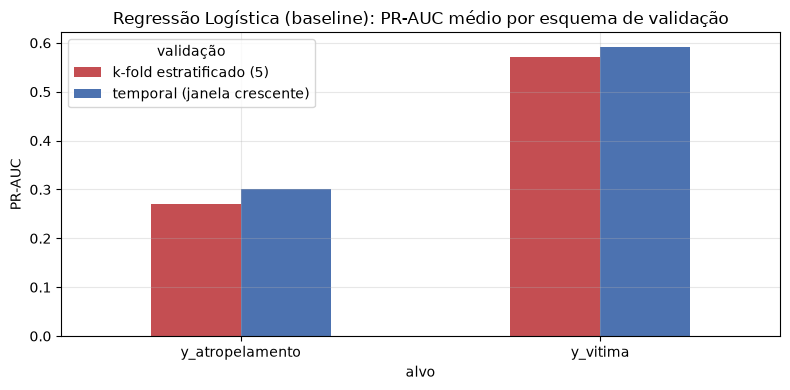

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
contraste.pivot(index="alvo", columns="validação", values="PR-AUC").plot.bar(ax=ax, rot=0, color=["#c44e52", "#4c72b0"])
ax.set(title="Regressão Logística (baseline): PR-AUC médio por esquema de validação", ylabel="PR-AUC")
plt.tight_layout()

**Por que o k-fold não se aplica aqui.** No painel, o mesmo local aparece em todos os
trimestres. O `StratifiedKFold` sorteia linhas: um fold treina com 2022 e valida em 2021, e
as features do trimestre seguinte (que já contêm o acidente que é o alvo do trimestre
anterior) acabam no treino. É vazamento temporal. A diferença entre as duas linhas do gráfico
mede esse vazamento para o baseline; para os seis modelos ela está no MLflow, nas métricas
`cv_estratificado_*` ao lado das `cv_temporal_*` de cada run. A especificação pede k-fold
"quando aplicável": demonstrar por que não se aplica vale mais do que aplicar errado.

`TimeSeriesSplit` também não resolve sozinho: ele corta por posição de linha, e cada trimestre
tem 1.807 linhas, então o corte cairia no meio de um trimestre. Os folds andam sobre os
**trimestres distintos**: o fold *i* treina em [0 .. k+i] e valida em k+i+1, e um teste
(`tests/test_validacao.py`) garante que o maior trimestre do treino é sempre menor que o
menor trimestre da validação. O Optuna usa os mesmos folds: otimizar hiperparâmetro em fold
vazado seria o mesmo erro.

**Vazamento de entidade não é problema.** O mesmo local está no treino e na validação, e isso
é intencional: em produção o modelo ranqueia locais já conhecidos (os 1.807 da grade), então a
sobreposição de entidades reflete o uso real. O que não pode é a sobreposição no tempo.

**Leave-One-Out** não se aplica: exigiria um ajuste por linha (mais de 14 mil no treino) e
teria o mesmo vazamento temporal do k-fold.

## 6. Por que acurácia não é usada

In [9]:
for alvo in ALVOS:
    teste = split_temporal(features, alvo)["teste"]
    print(f"{alvo}: um modelo que diz 'nenhum local' acerta {1 - teste[alvo].mean():.1%} do teste e não ranqueia nada")

y_vitima: um modelo que diz 'nenhum local' acerta 75.0% do teste e não ranqueia nada
y_atropelamento: um modelo que diz 'nenhum local' acerta 97.9% do teste e não ranqueia nada


Com 2% a 26% de positivos, a acurácia premia o modelo que nunca aponta risco. As métricas de
seleção são as da seção 5: PR-AUC (comparado com a prevalência, que é o PR-AUC de um ranking
aleatório), Recall@50 e Recall@100 por trimestre (dos acidentes que aconteceram, quantos
estavam entre os 50 ou 100 locais apontados), ROC-AUC como comparação secundária, e F1,
precisão e recall no limiar escolhido na validação (o que maximiza o F1). Os resultados dos
modelos estão no MLflow (experimentos `01_baseline`, `02_comparacao_modelos` e
`03_otimizacao_hiperparametros`).